# Sampling and Statistical Inference in Neuroscience

**Interactive Python practical · Cognitive neuroscience · Beginner–intermediate**

> **Learning goals:** simulate experimental populations, explore sampling uncertainty, distinguish SD from SEM, visualise the central limit theorem, and interpret normal versus Student’s *t* distributions.

This notebook uses **synthetic participant-level mean reaction times** from a hypothetical visual detection task, followed by simulated neural-response amplitudes. In a real experiment, each participant would complete multiple trials; trial-level responses would be quality-controlled and summarised before participant-level inference.

**How to use:** run the cells in order using **Run All** (or `Shift + Enter` one cell at a time). Every graphical analysis displays its figure directly below the corresponding code cell. All random draws are reproducible.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Reproducible simulations and consistent, publication-style plots.
rng = np.random.default_rng(42)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "savefig.dpi": 150, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "semibold",
    "axes.labelsize": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True,
    "axes.axisbelow": True, "grid.alpha": 0.16,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "legend.frameon": False,
})


## 1. Simulate a population of reaction times

Imagine a large cognitive neuroscience study with **12,000 participants** performing a visual detection task. For simplicity, model each participant’s *mean* reaction time as normally distributed with population mean **310 ms** and standard deviation **45 ms**. These are illustrative values, not empirical normative estimates. Why might individual trial-level reaction times be less normally distributed than participant-level averages?

Simulated population mean: 309.48 ms
Simulated population SD: 45.23 ms


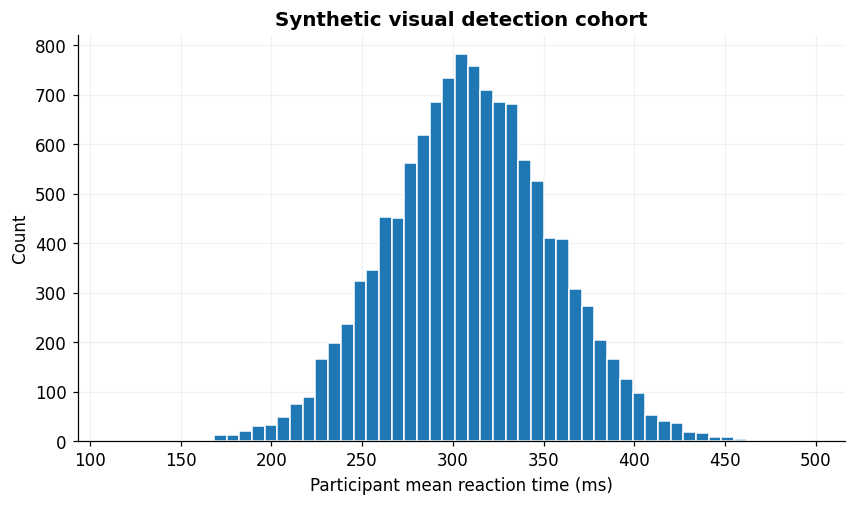

In [2]:
population_size = 12_000
mu, sigma = 310, 45  # milliseconds
reaction_times = rng.normal(loc=mu, scale=sigma, size=population_size)
print(f"Simulated population mean: {reaction_times.mean():.2f} ms")
print(f"Simulated population SD: {reaction_times.std(ddof=0):.2f} ms")
fig, ax = plt.subplots()
ax.hist(reaction_times, bins=55, edgecolor="white")
ax.set(xlabel="Participant mean reaction time (ms)", ylabel="Count", title="Synthetic visual detection cohort")
plt.show()

**Try it yourself:** Increase between-participant variability while keeping the population mean fixed. What happens to the shape of the population distribution?

## 2. Draw a random sample

A small independent group of **eight participants** completes the same task and has an observed mean reaction time of **335 ms**. Is this slower than expected under the reference population model? First, draw one random sample of eight participants from the simulated cohort.

Sample reaction times: [312.2 316.2 283.5 301.2 351.2 379.7 355.2 254.1]
Sample mean: 319.16 ms
Sample SD (ddof=1): 41.19 ms


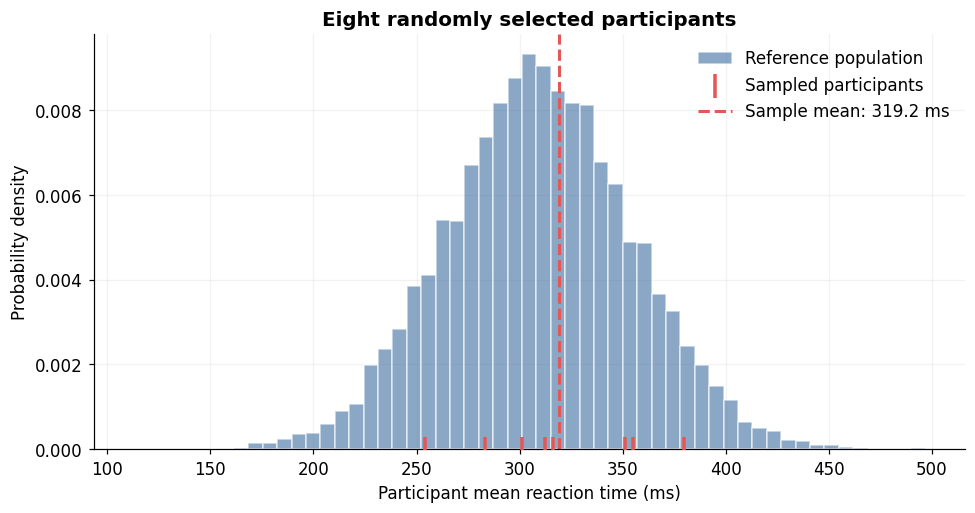

In [3]:
n = 8
sample = rng.choice(reaction_times, size=n, replace=True)
print("Sample reaction times:", np.round(sample, 1))
print(f"Sample mean: {sample.mean():.2f} ms")
print(f"Sample SD (ddof=1): {sample.std(ddof=1):.2f} ms")

# Compare the selected participants with the full reference population.
fig, ax = plt.subplots()
ax.hist(reaction_times, bins=55, density=True, alpha=0.65,
        color="#4C78A8", edgecolor="white", label="Reference population")
ax.scatter(sample, np.zeros_like(sample), marker="|", s=230,
           linewidths=2.3, color="#E45756", label="Sampled participants", zorder=4)
ax.axvline(sample.mean(), color="#E45756", linestyle="--", linewidth=2,
           label=f"Sample mean: {sample.mean():.1f} ms")
ax.set(xlabel="Participant mean reaction time (ms)", ylabel="Probability density",
       title="Eight randomly selected participants")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 3. Build a null sampling distribution

Under the null hypothesis, the eight participants are drawn from the same distribution as the reference cohort. Simulate **10,000 independent groups of eight**, calculate each group’s mean, and estimate the proportion with mean reaction time **at least 335 ms**. This is an upper-tail test for slower responses.

Simulated one-sided tail probability: 0.0521 (5.21%)


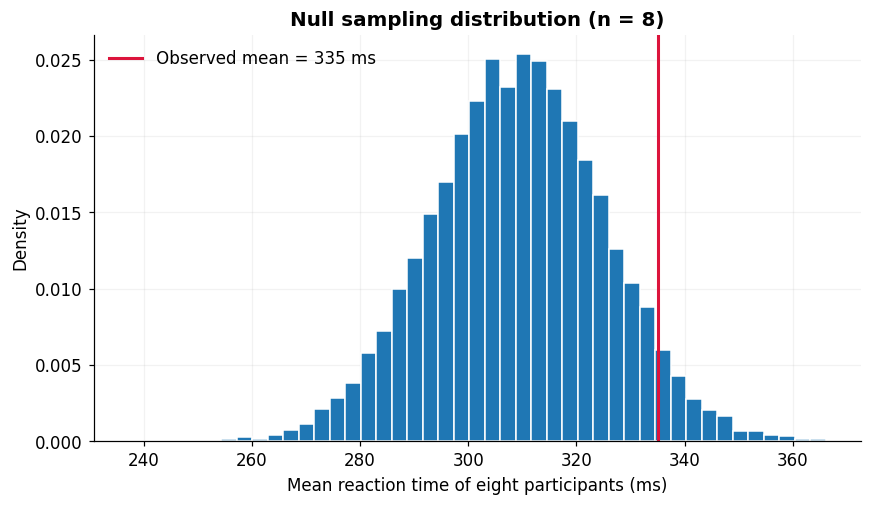

In [4]:
n_simulations = 10_000
sample_means_8 = rng.choice(reaction_times, size=(n_simulations, 8), replace=True).mean(axis=1)
observed_mean = 335
p_simulated = np.mean(sample_means_8 >= observed_mean)
print(f"Simulated one-sided tail probability: {p_simulated:.4f} ({100*p_simulated:.2f}%)")
fig, ax = plt.subplots()
ax.hist(sample_means_8, bins=45, density=True, edgecolor="white")
ax.axvline(observed_mean, color="crimson", linewidth=2, label="Observed mean = 335 ms")
ax.set(xlabel="Mean reaction time of eight participants (ms)", ylabel="Density", title="Null sampling distribution (n = 8)")
ax.legend(); plt.show()

The fraction of simulated means at least as large as 335 ms estimates a **one-sided p-value**, conditional on the specified null model. It does **not** measure the probability that the null hypothesis is true. The simulation samples with replacement from a finite synthetic cohort; the model is deliberately simplified.

## 4. What happens when sample size increases?

Compare independent groups of **8, 24 and 60 participants**, all with the same observed mean of 335 ms. Why does an identical difference from the reference mean provide different evidence at different sample sizes?

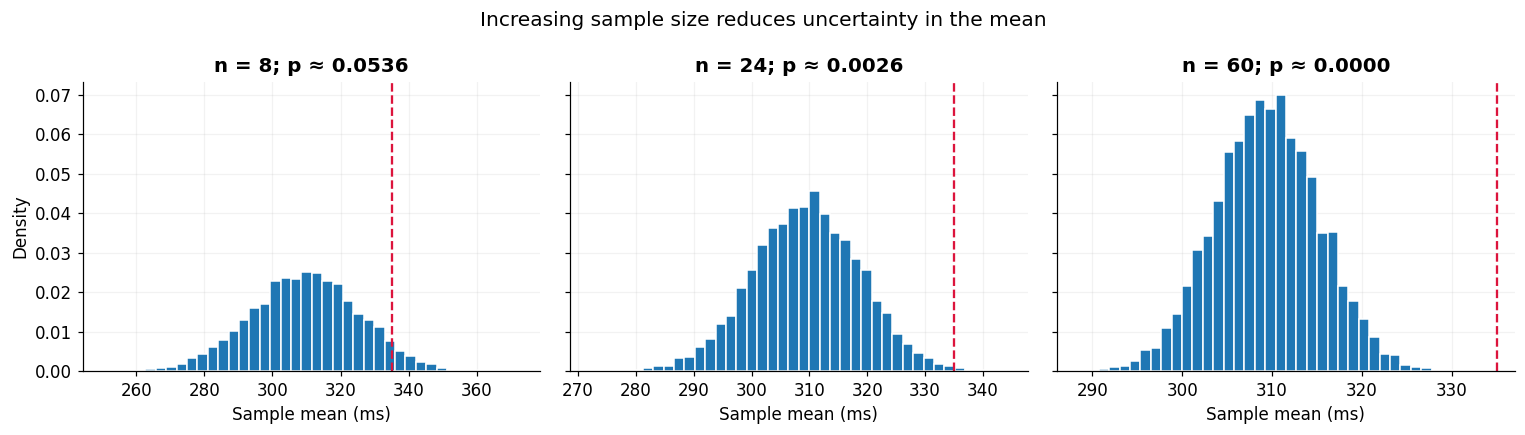

In [5]:
sample_sizes = [8, 24, 60]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, size in zip(axes, sample_sizes):
    means = rng.choice(reaction_times, size=(n_simulations, size), replace=True).mean(axis=1)
    probability = np.mean(means >= observed_mean)
    ax.hist(means, bins=40, density=True, edgecolor="white")
    ax.axvline(observed_mean, color="crimson", linestyle="--")
    ax.set(title=f"n = {size}; p ≈ {probability:.4f}", xlabel="Sample mean (ms)")
axes[0].set_ylabel("Density")
fig.suptitle("Increasing sample size reduces uncertainty in the mean")
plt.tight_layout(); plt.show()

**Discussion:** A 25 ms difference may be meaningful or trivial depending on the task and clinical context. How do statistical evidence, measurement reliability and practical importance differ?

## 5. Standard deviation versus standard error

The **standard deviation (SD)** describes between-participant variation in mean reaction times. The **standard error of the mean (SEM)** describes variation in sample means across repeated studies. Under independent sampling, $\mathrm{SEM}=\sigma/\sqrt{n}$. Check this relationship in a simulation, and contrast it with the SD *within* each sample.

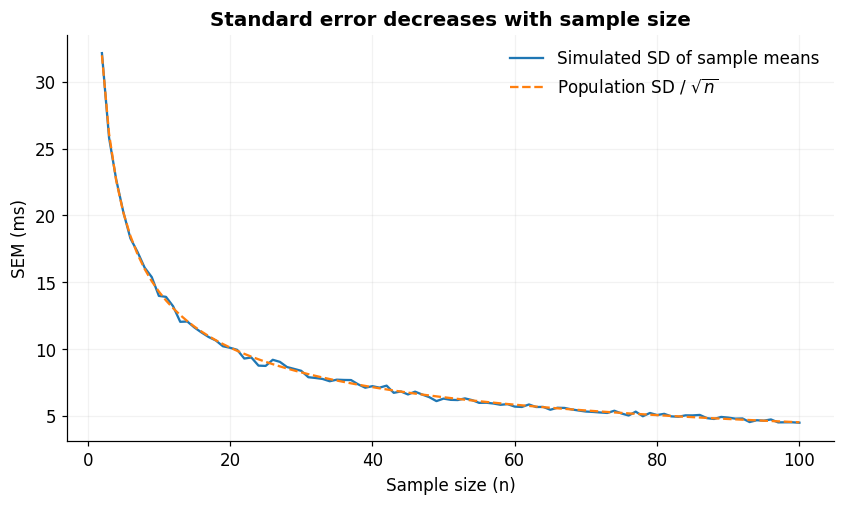

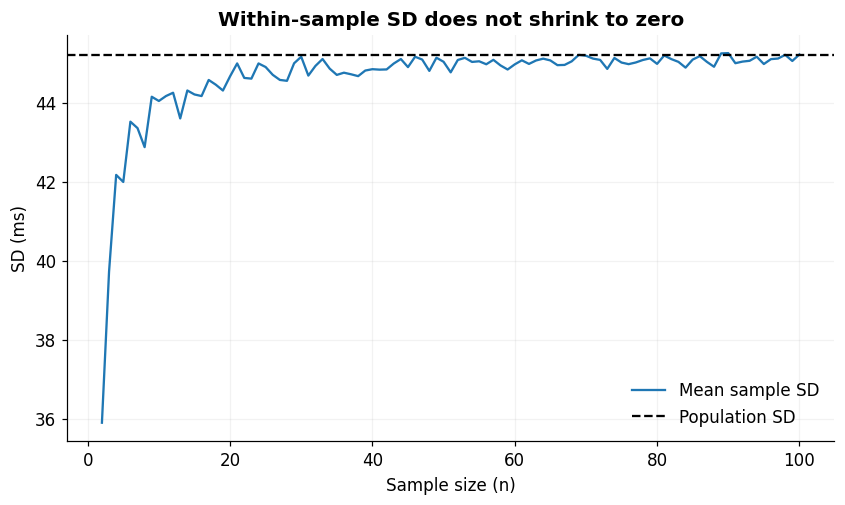

In [6]:
ns = np.arange(2, 101)
repeats = 1_000
empirical_sem = []
mean_within_sample_sd = []
for size in ns:
    draws = rng.choice(reaction_times, size=(repeats, size), replace=True)
    empirical_sem.append(draws.mean(axis=1).std(ddof=1))
    mean_within_sample_sd.append(draws.std(axis=1, ddof=1).mean())
empirical_sem = np.asarray(empirical_sem)
mean_within_sample_sd = np.asarray(mean_within_sample_sd)
theoretical_sem = reaction_times.std(ddof=0) / np.sqrt(ns)
fig, ax = plt.subplots()
ax.plot(ns, empirical_sem, label="Simulated SD of sample means")
ax.plot(ns, theoretical_sem, "--", label=r"Population SD / $\sqrt{n}$")
ax.set(xlabel="Sample size (n)", ylabel="SEM (ms)", title="Standard error decreases with sample size")
ax.legend(); plt.show()
fig, ax = plt.subplots()
ax.plot(ns, mean_within_sample_sd, label="Mean sample SD")
ax.axhline(reaction_times.std(ddof=0), color="black", linestyle="--", label="Population SD")
ax.set(xlabel="Sample size (n)", ylabel="SD (ms)", title="Within-sample SD does not shrink to zero")
ax.legend(); plt.show()

**Try it yourself:** Change the reference population SD from 45 to 70 ms and rerun the notebook. Which curves change? Why does the average sample SD not approach zero as sample size increases?

## 6. Central limit theorem: a non-normal neural measurement

Now imagine a synthetic neural response amplitude with two subgroups (for example, two response regimes). The resulting population distribution is bimodal. The central limit theorem predicts that averages of sufficiently large independent samples become approximately normal when the underlying distribution has finite variance, even when the raw observations are non-normal.

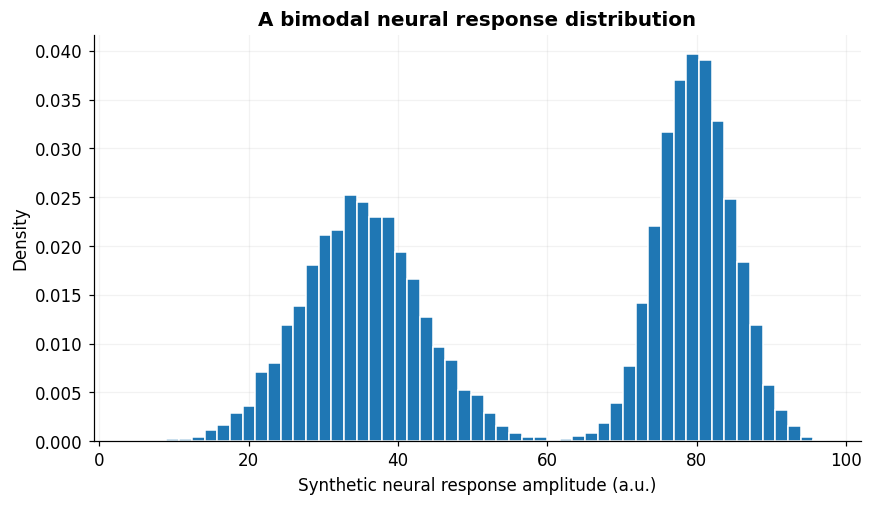

In [7]:
n_population = 10_000
component = rng.random(n_population) < 0.5
neural_amplitudes = np.where(component, rng.normal(35, 8, n_population), rng.normal(80, 5, n_population))
fig, ax = plt.subplots()
ax.hist(neural_amplitudes, bins=55, density=True, edgecolor="white")
ax.set(xlabel="Synthetic neural response amplitude (a.u.)", ylabel="Density", title="A bimodal neural response distribution")
plt.show()

Draw repeated samples of $n=3$, $8$, $16$ and $40$ neural response amplitudes. Compare the shape of their sample-mean distributions.

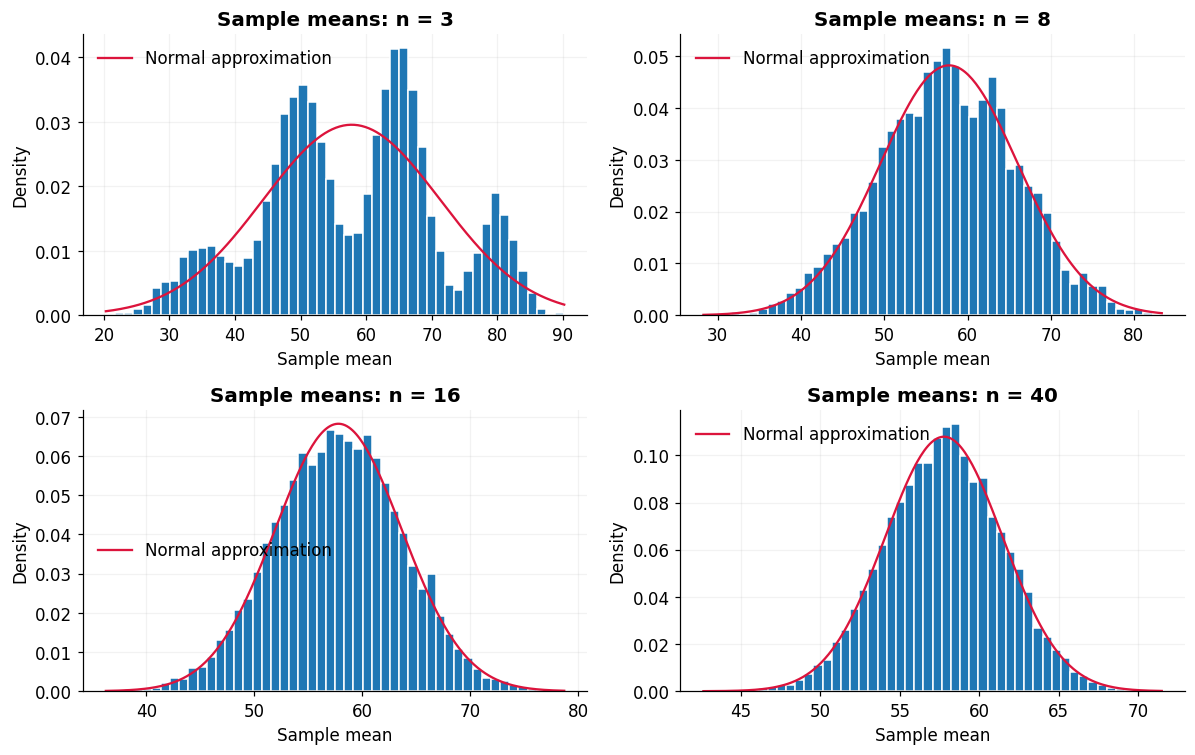

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, size in zip(axes.flat, [3, 8, 16, 40]):
    means = rng.choice(neural_amplitudes, size=(10_000, size), replace=True).mean(axis=1)
    ax.hist(means, bins=50, density=True, edgecolor="white")
    x = np.linspace(means.min(), means.max(), 250)
    ax.plot(x, stats.norm.pdf(x, loc=neural_amplitudes.mean(), scale=neural_amplitudes.std(ddof=0)/np.sqrt(size)),
            color="crimson", label="Normal approximation")
    ax.set(title=f"Sample means: n = {size}", xlabel="Sample mean", ylabel="Density")
    ax.legend()
plt.tight_layout(); plt.show()

**Try it yourself:** Alter the proportions of the two response regimes (e.g. 75% versus 25%). How does this affect the sampling distribution at small sample sizes?

## 7. SEM for non-normal observations

Check whether the inverse-square-root scaling also holds for the bimodal neural-response distribution. It does under independent sampling with finite variance; normality of the raw observations is not required.

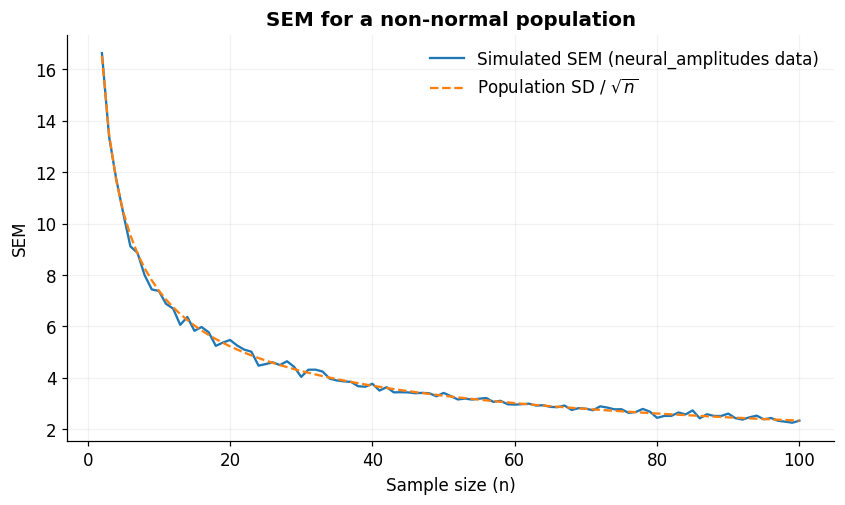

In [9]:
ns = np.arange(2, 101)
sem_neural_amplitudes = np.array([
    rng.choice(neural_amplitudes, size=(500, size), replace=True).mean(axis=1).std(ddof=1)
    for size in ns
])
fig, ax = plt.subplots()
ax.plot(ns, sem_neural_amplitudes, label="Simulated SEM (neural_amplitudes data)")
ax.plot(ns, neural_amplitudes.std(ddof=0)/np.sqrt(ns), "--", label=r"Population SD / $\sqrt{n}$")
ax.set(xlabel="Sample size (n)", ylabel="SEM", title="SEM for a non-normal population")
ax.legend(); plt.show()

## 8. Standard normal versus Student’s t-distribution

When independent observations are normally distributed and the population SD is known, $(\bar X-\mu)/(\sigma/\sqrt n)$ follows a standard normal distribution. When the SD is estimated from the sample, $(\bar X-\mu)/(s/\sqrt n)$ follows Student’s *t*-distribution with $n-1$ degrees of freedom. Compare their tails and consider why small-sample inference requires care.

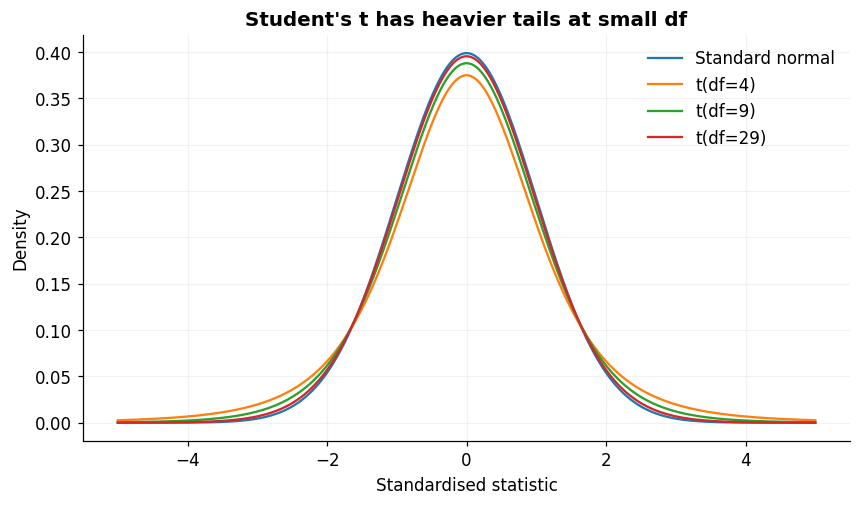

One-sided normal tail beyond 3: 0.00135
One-sided t(4) tail beyond 3: 0.01997
Two-sided normal p-value: 0.00270
Two-sided t(4) p-value: 0.03994


In [10]:
x = np.linspace(-5, 5, 600)
fig, ax = plt.subplots()
ax.plot(x, stats.norm.pdf(x), label="Standard normal")
for df in [4, 9, 29]:
    ax.plot(x, stats.t.pdf(x, df), label=f"t(df={df})")
ax.set(xlabel="Standardised statistic", ylabel="Density", title="Student's t has heavier tails at small df")
ax.legend(); plt.show()
t_value = 3
print(f"One-sided normal tail beyond 3: {stats.norm.sf(t_value):.5f}")
print(f"One-sided t(4) tail beyond 3: {stats.t.sf(t_value, df=4):.5f}")
print(f"Two-sided normal p-value: {2*stats.norm.sf(abs(t_value)):.5f}")
print(f"Two-sided t(4) p-value: {2*stats.t.sf(abs(t_value), df=4):.5f}")

**Discussion:** When would a *t*-test be justified for behavioural reaction-time summaries? Would it necessarily be appropriate for strongly right-skewed single-trial reaction times? Consider independence, outliers and distributional assumptions.

## 9. Advanced exercise: create a heterogeneous neural population

Construct a three-component mixture representing hypothetical low-, medium- and high-response regimes. Plot the distribution and examine how the distribution of sample means changes as $n$ increases. The mixture is purely illustrative and should not be interpreted as evidence for real neural subtypes.

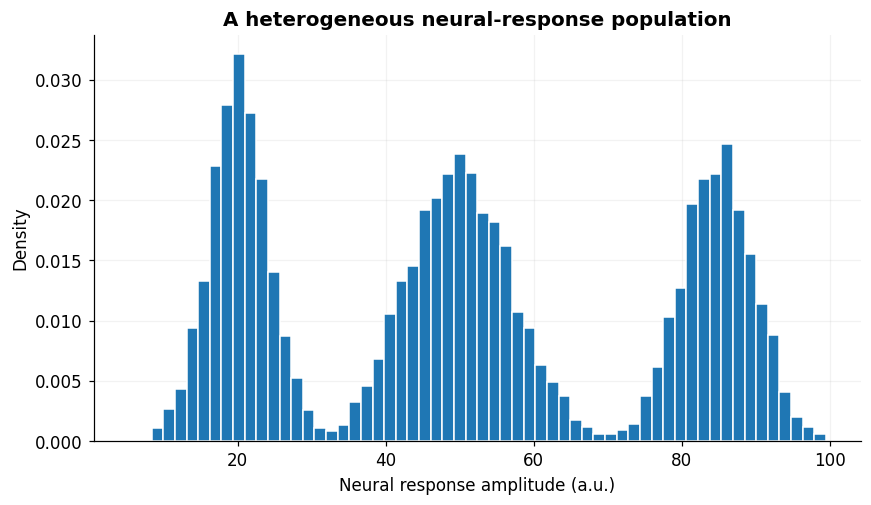

In [11]:
weights = [0.3, 0.4, 0.3]
centres = [20, 50, 85]
scales = [4, 7, 5]
components = rng.choice(3, size=10_000, p=weights)
heterogeneous_responses = rng.normal(np.asarray(centres)[components], np.asarray(scales)[components])
fig, ax = plt.subplots()
ax.hist(heterogeneous_responses, bins=60, density=True, edgecolor="white")
ax.set(xlabel="Neural response amplitude (a.u.)", ylabel="Density", title="A heterogeneous neural-response population")
plt.show()
# Exercise: adapt the CLT simulation above for heterogeneous_responses samples.

## 10. Check your understanding

1. Why does the distribution of sample means become narrower as the number of participants increases?
2. What does a simulated upper-tail probability of 0.07 tell you about a group with slower reaction times? What does it *not* tell you?
3. Distinguish between variability across participants and uncertainty about the population mean.
4. Why can a bimodal neural-response distribution produce approximately normal sample means?
5. When should a *t*-distribution be used rather than a standard normal distribution?
6. Design a simulation to investigate how a small number of unusually slow participants affects the sample mean and median.

**Extension:** Replace the normal reaction-time model with a lognormal distribution and investigate whether the conclusions change for small samples.